In [1]:
from pathlib import Path
import pandas as pd

project_root = Path(
    r"C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection"
)
raw_folder = project_root / "data" / "raw" / "paderborn"

registry = pd.read_csv(
    project_root / "metadata" / "recording_registry.csv"
)

analysis_development = registry[
    (registry["partition"] == "development")
    & (~registry["needs_timing_review"])
].copy()

print("Selected development recordings:", len(analysis_development))

Selected development recordings: 272


In [2]:
comparison_pool = analysis_development[
    (analysis_development["speed_code"] == "N15")
    & (analysis_development["torq_code"] == "M07")
    & (analysis_development["force_code"] == "F10")
].copy()

print(comparison_pool.groupby(["bearing_id", "condition"]).size())

bearing_id  condition
K001        healthy      16
K002        healthy      19
KA04        faulty       18
KI04        faulty       17
dtype: int64


In [3]:
example_records = comparison_pool.sort_values(
    ["bearing_id", "recording_no"]
).drop_duplicates("bearing_id", keep="first")

example_records[[
    "recording_id",
    "bearing_id",
    "condition",
    "recording_no"
]]

,recording_id,bearing_id,condition,recording_no
60,N15_M07_F10_K001_1,K001,healthy,1
140,N15_M07_F10_K002_1,K002,healthy,1
300,N15_M07_F10_KA04_1,KA04,faulty,1
460,N15_M07_F10_KI04_1,KI04,faulty,1


In [4]:
from scipy.io import loadmat

def load_vibration(path):
    recording = loadmat(path)[path.stem][0, 0]
    channels = recording["Y"].ravel()
    names = [channel["Name"].item() for channel in channels]

    vibration = channels[names.index("vibration_1")]
    x = vibration["Data"].ravel()

    axis_index = int(vibration["XIndex"].item()) - 1
    t_stored = recording["X"].ravel()[axis_index]["Data"].ravel()

    return x, t_stored

In [5]:
row = example_records.iloc[0]
path = raw_folder / row["relative_path"]

x, t_stored = load_vibration(path)

print("Recording:", row["recording_id"])
print("Vibration samples:", x.size)
print("Time values:", t_stored.size)

Recording: N15_M07_F10_K001_1
Vibration samples: 256001
Time values: 256001


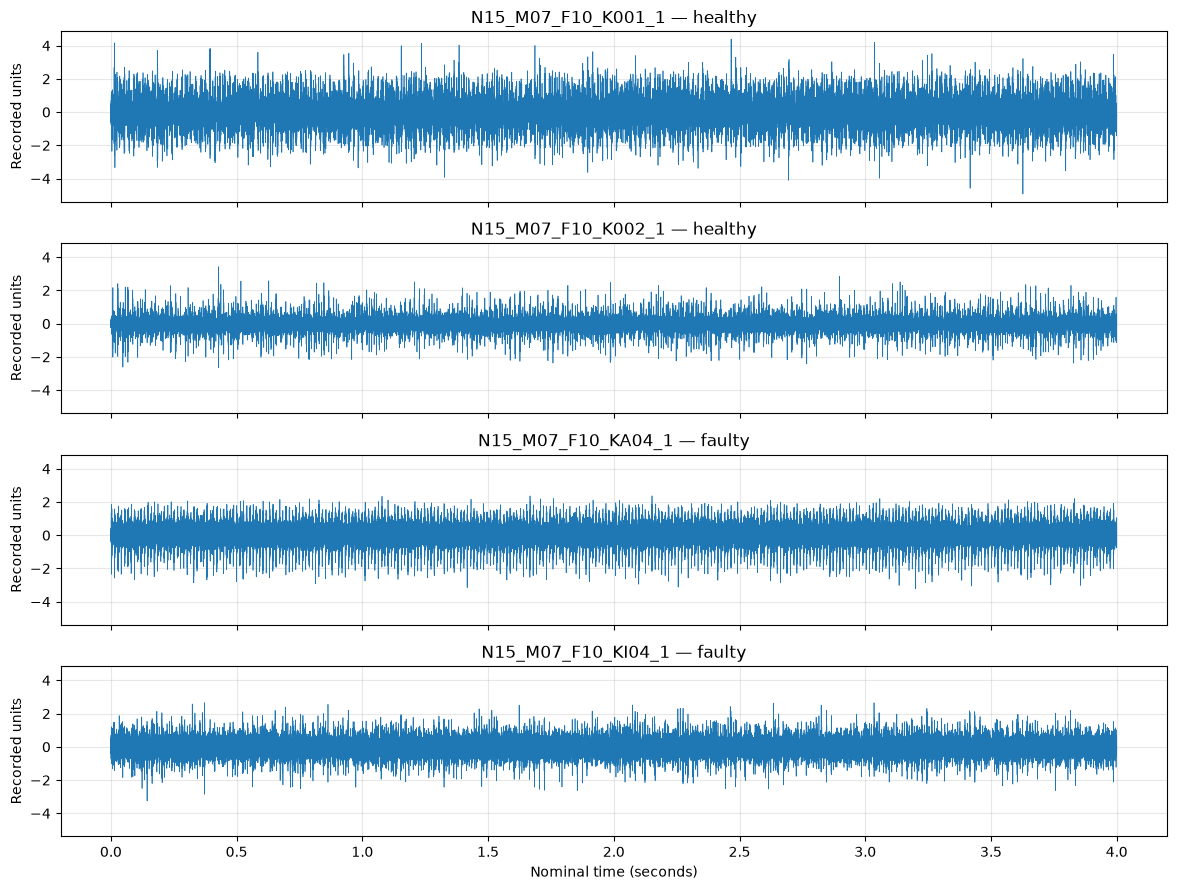

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    4, 1, figsize=(12, 9),
    sharex=True, sharey=True
)

for i in range(4):
    row = example_records.iloc[i]
    path = raw_folder / row["relative_path"]
    x, t_stored = load_vibration(path)

    fs = float(row["nominal_fs_hz"])
    t = np.arange(x.size) / fs

    axes[i].plot(t, x, linewidth=0.5)
    axes[i].set_title(f"{row['recording_id']} — {row['condition']}")
    axes[i].set_ylabel("Recorded units")
    axes[i].grid(alpha=0.3)

axes[-1].set_xlabel("Nominal time (seconds)")
plt.tight_layout()
plt.show()

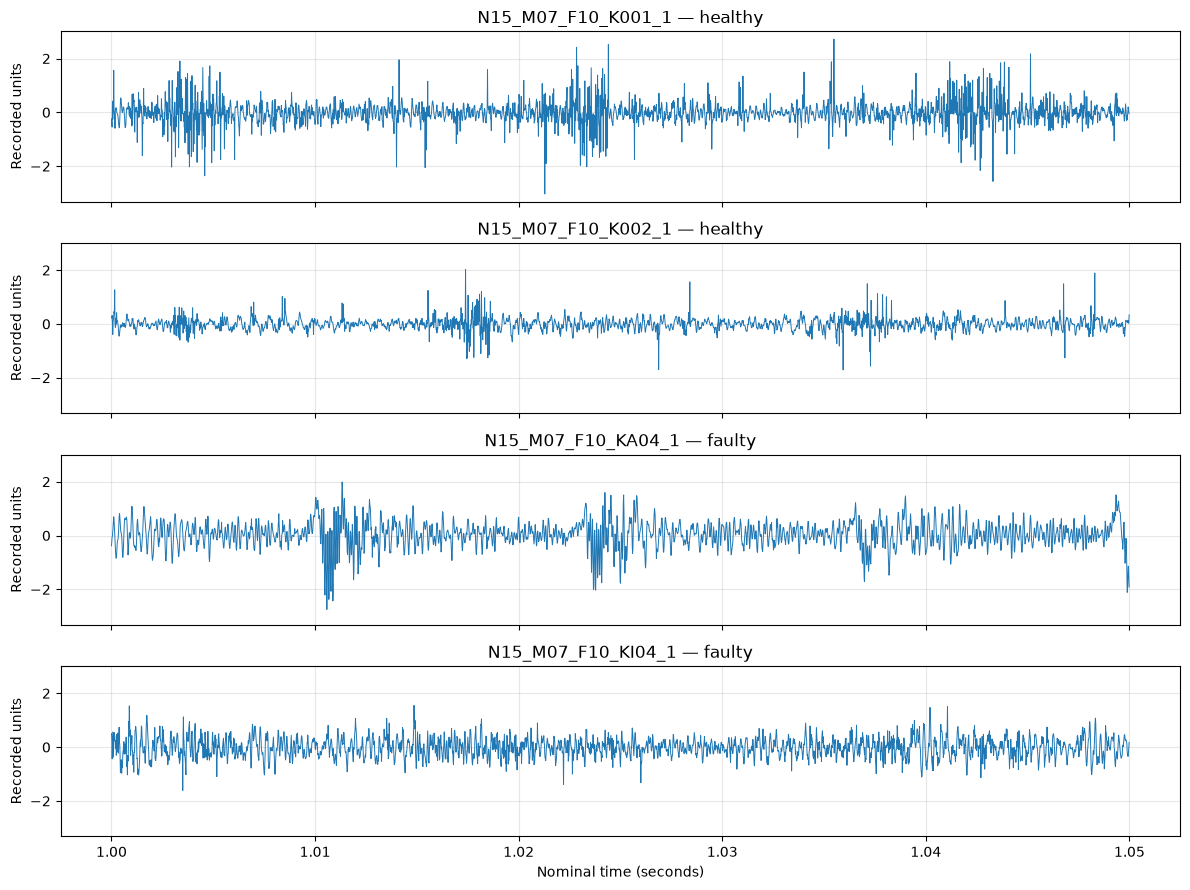

In [7]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 9),
    sharex=True, sharey=True
)

for i in range(4):
    row = example_records.iloc[i]
    x, t_stored = load_vibration(raw_folder / row["relative_path"])

    fs = float(row["nominal_fs_hz"])
    t = np.arange(x.size) / fs
    mask = (t >= 1.00) & (t < 1.05)

    axes[i].plot(t[mask], x[mask], linewidth=0.7)
    axes[i].set_title(f"{row['recording_id']} — {row['condition']}")
    axes[i].set_ylabel("Recorded units")
    axes[i].grid(alpha=0.3)

axes[-1].set_xlabel("Nominal time (seconds)")
plt.tight_layout()
plt.show()

In [8]:
row = example_records[
    example_records["bearing_id"] == "K001"
].iloc[0]

x, t_stored = load_vibration(raw_folder / row["relative_path"])
fs = float(row["nominal_fs_hz"])

x_centered = x - x.mean()
N = x.size

print("Recording:", row["recording_id"])
print("Samples:", N)
print("Mean before centering:", x.mean())
print("Mean after centering:", x_centered.mean())

Recording: N15_M07_F10_K001_1
Samples: 256001
Mean before centering: -0.018842242058867857
Mean after centering: 6.272735586258751e-18


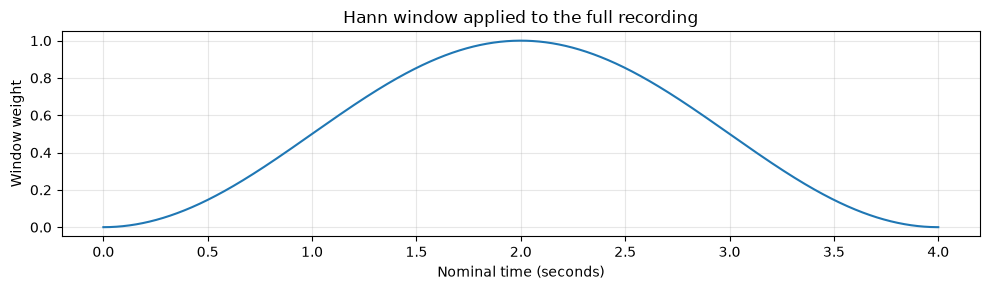

In [9]:
from scipy.signal.windows import hann

window = hann(N, sym=False)
x_windowed = x_centered * window

plt.figure(figsize=(10, 3))
plt.plot(np.arange(N) / fs, window)
plt.xlabel("Nominal time (seconds)")
plt.ylabel("Window weight")
plt.title("Hann window applied to the full recording")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
X = np.fft.rfft(x_windowed)
f_fft = np.fft.rfftfreq(N, d=1 / fs)

print("FFT values:", X.size)
print("Frequency bins:", f_fft.size)
print(f"Bin spacing: {fs / N:.6f} Hz")

FFT values: 128001
Frequency bins: 128001
Bin spacing: 0.249999 Hz


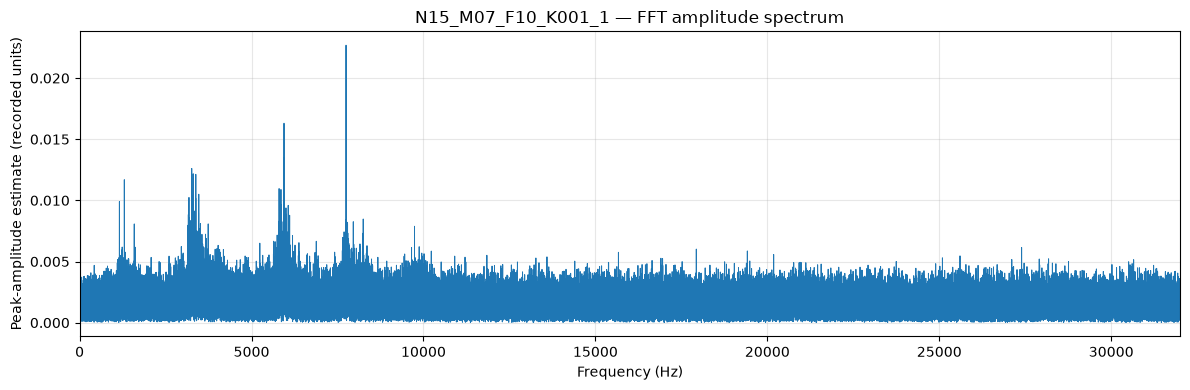

In [11]:
amplitude = np.abs(X) / window.sum()

if N % 2 == 0:
    amplitude[1:-1] *= 2
else:
    amplitude[1:] *= 2

plt.figure(figsize=(12, 4))
plt.plot(f_fft, amplitude, linewidth=0.7)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Peak-amplitude estimate (recorded units)")
plt.title(f"{row['recording_id']} — FFT amplitude spectrum")
plt.xlim(0, fs / 2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
peak_index = np.argmax(amplitude[1:]) + 1

print(f"Peak frequency: {f_fft[peak_index]:.2f} Hz")
print(f"Peak-amplitude estimate: {amplitude[peak_index]:.6f}")

Peak frequency: 7747.72 Hz
Peak-amplitude estimate: 0.022688


In [13]:
def fft_amplitude(x, fs):
    # Remove the constant offset.
    x_centered = x - x.mean()
    N = x.size

    # Apply a Hann window to reduce spectral leakage.
    window = hann(N, sym=False)
    X = np.fft.rfft(x_centered * window)

    # Calculate the frequency corresponding to each FFT value.
    frequencies = np.fft.rfftfreq(N, d=1 / fs)

    # Scale FFT magnitudes into one-sided amplitude estimates.
    amplitude = np.abs(X) / window.sum()

    if N % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2

    return frequencies, amplitude

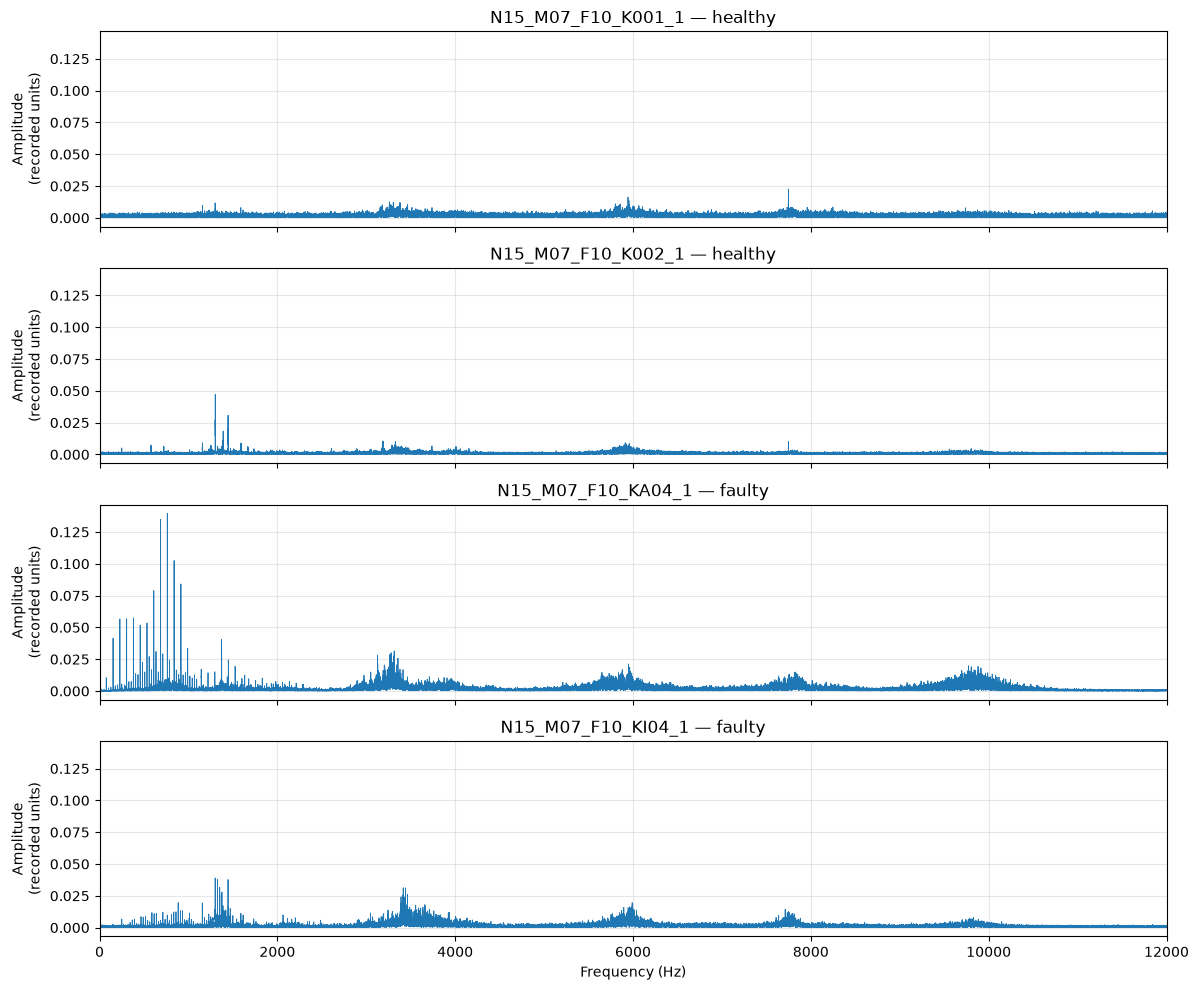

In [16]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 10),
    sharex=True,
    sharey=True
)

for ax, (_, row) in zip(axes, example_records.iterrows()):
    # Load this recording.
    x, _ = load_vibration(raw_folder / row["relative_path"])
    fs = float(row["nominal_fs_hz"])

    # Calculate its frequency and amplitude arrays.
    frequencies, amplitude = fft_amplitude(x, fs)

    # Plot the spectrum.
    ax.plot(frequencies, amplitude, linewidth=0.6)
    ax.set_title(f"{row['recording_id']} — {row['condition']}")
    ax.set_ylabel("Amplitude\n(recorded units)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, 12_000)

plt.tight_layout()
plt.show()

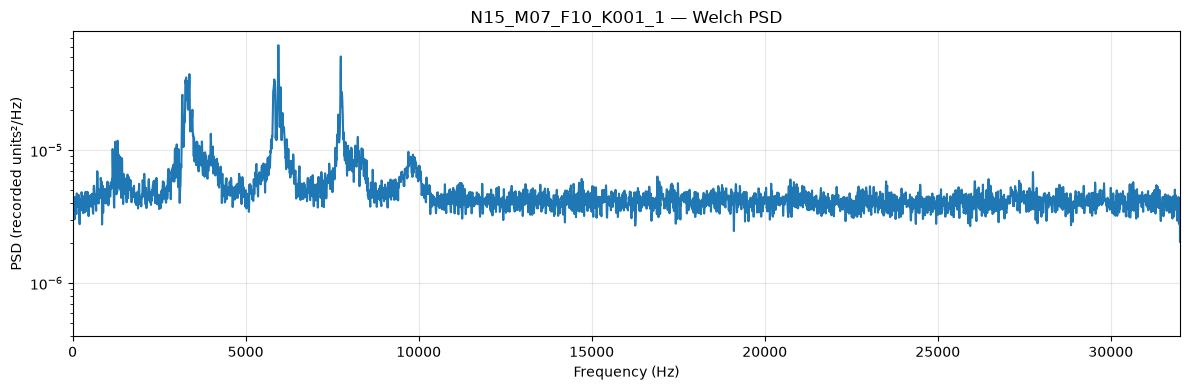

In [17]:
from scipy.signal import welch

# 1. Reload the healthy K001 example.
row = example_records[
    example_records["bearing_id"] == "K001"
].iloc[0]

x, _ = load_vibration(raw_folder / row["relative_path"])
fs = float(row["nominal_fs_hz"])

# 2. Define the segment length.
segment_length = 8192

# 3. Estimate the power spectral density.
f_psd, psd = welch(
    x,
    fs=fs,
    window="hann",
    nperseg=segment_length,
    noverlap=segment_length // 2,
    detrend="constant",
    scaling="density"
)

# 4. Plot the PSD.
plt.figure(figsize=(12, 4))
plt.semilogy(f_psd, psd)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (recorded units²/Hz)")
plt.title(f"{row['recording_id']} — Welch PSD")
plt.xlim(0, fs / 2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

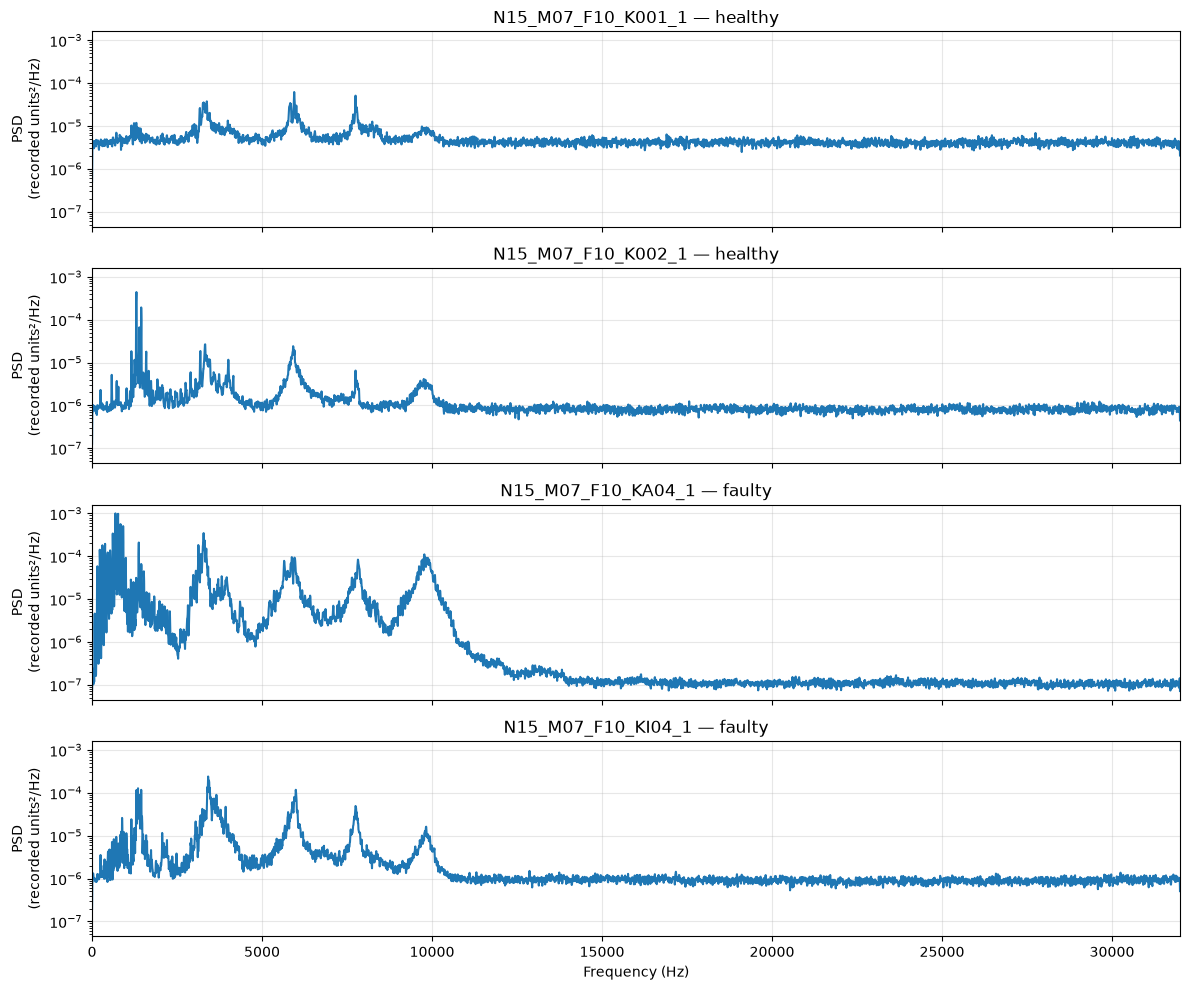

In [18]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 10),
    sharex=True, sharey=True
)

for ax, (_, row) in zip(axes, example_records.iterrows()):
    x, _ = load_vibration(raw_folder / row["relative_path"])
    fs = float(row["nominal_fs_hz"])

    frequencies, psd = welch(
        x,
        fs=fs,
        window="hann",
        nperseg=8192,
        noverlap=4096,
        detrend="constant",
        scaling="density"
    )

    ax.semilogy(frequencies, psd)
    ax.set_title(f"{row['recording_id']} — {row['condition']}")
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, fs / 2)

plt.tight_layout()
plt.show()

In [19]:
from scipy.signal import spectrogram

# Reload the healthy K001 example.
row = example_records[
    example_records["bearing_id"] == "K001"
].iloc[0]

x, _ = load_vibration(raw_folder / row["relative_path"])
fs = float(row["nominal_fs_hz"])

# Calculate a PSD for each successive segment.
f_spec, t_spec, psd_spec = spectrogram(
    x,
    fs=fs,
    window="hann",
    nperseg=8192,
    noverlap=4096,
    detrend="constant",
    scaling="density",
    mode="psd"
)

print("Frequency bins:", f_spec.size)
print("Time segments:", t_spec.size)
print("Spectrogram shape:", psd_spec.shape)

Frequency bins: 4097
Time segments: 61
Spectrogram shape: (4097, 61)


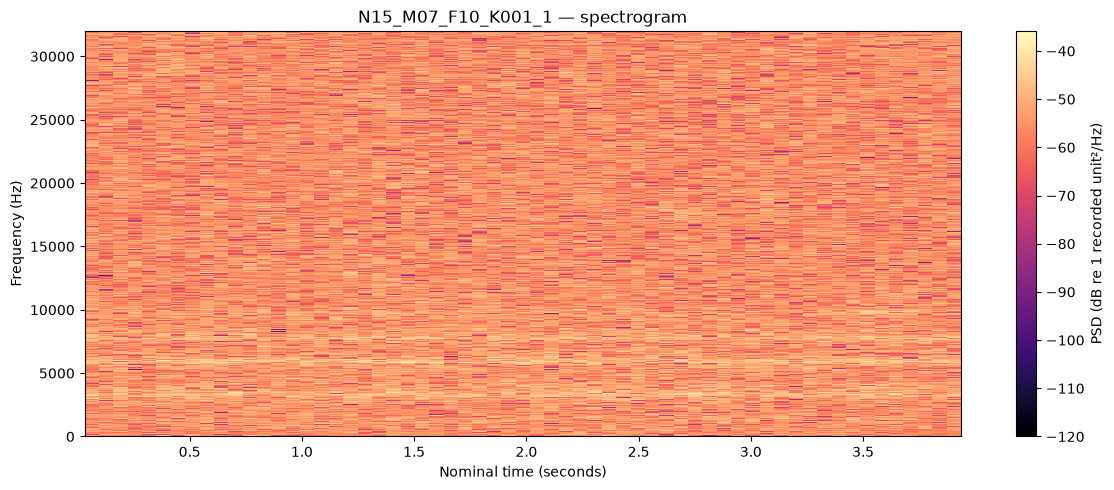

In [20]:
# Convert PSD to decibels for displaying strong and weak regions.
psd_db = 10 * np.log10(np.maximum(psd_spec, 1e-12))

plt.figure(figsize=(12, 5))

mesh = plt.pcolormesh(
    t_spec,
    f_spec,
    psd_db,
    shading="auto",
    cmap="magma"
)

plt.xlabel("Nominal time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title(f"{row['recording_id']} — spectrogram")
plt.ylim(0, fs / 2)

plt.colorbar(
    mesh,
    label="PSD (dB re 1 recorded unit²/Hz)"
)

plt.tight_layout()
plt.show()

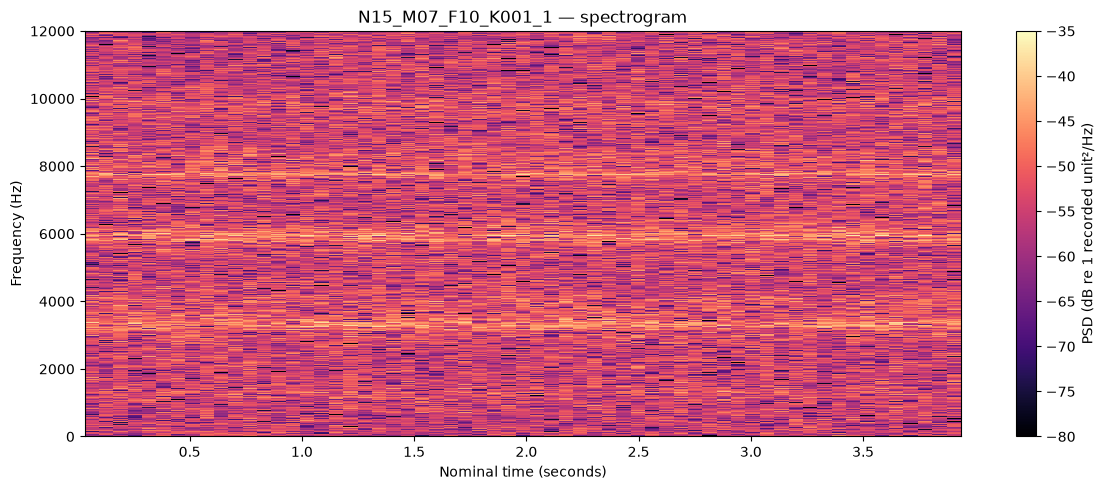

In [21]:
plt.figure(figsize=(12, 5))

mesh = plt.pcolormesh(
    t_spec,
    f_spec,
    psd_db,
    shading="auto",
    cmap="magma",
    vmin=-80,
    vmax=-35
)

plt.xlabel("Nominal time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title(f"{row['recording_id']} — spectrogram")
plt.ylim(0, 12_000)

plt.colorbar(mesh, label="PSD (dB re 1 recorded unit²/Hz)")
plt.tight_layout()
plt.show()

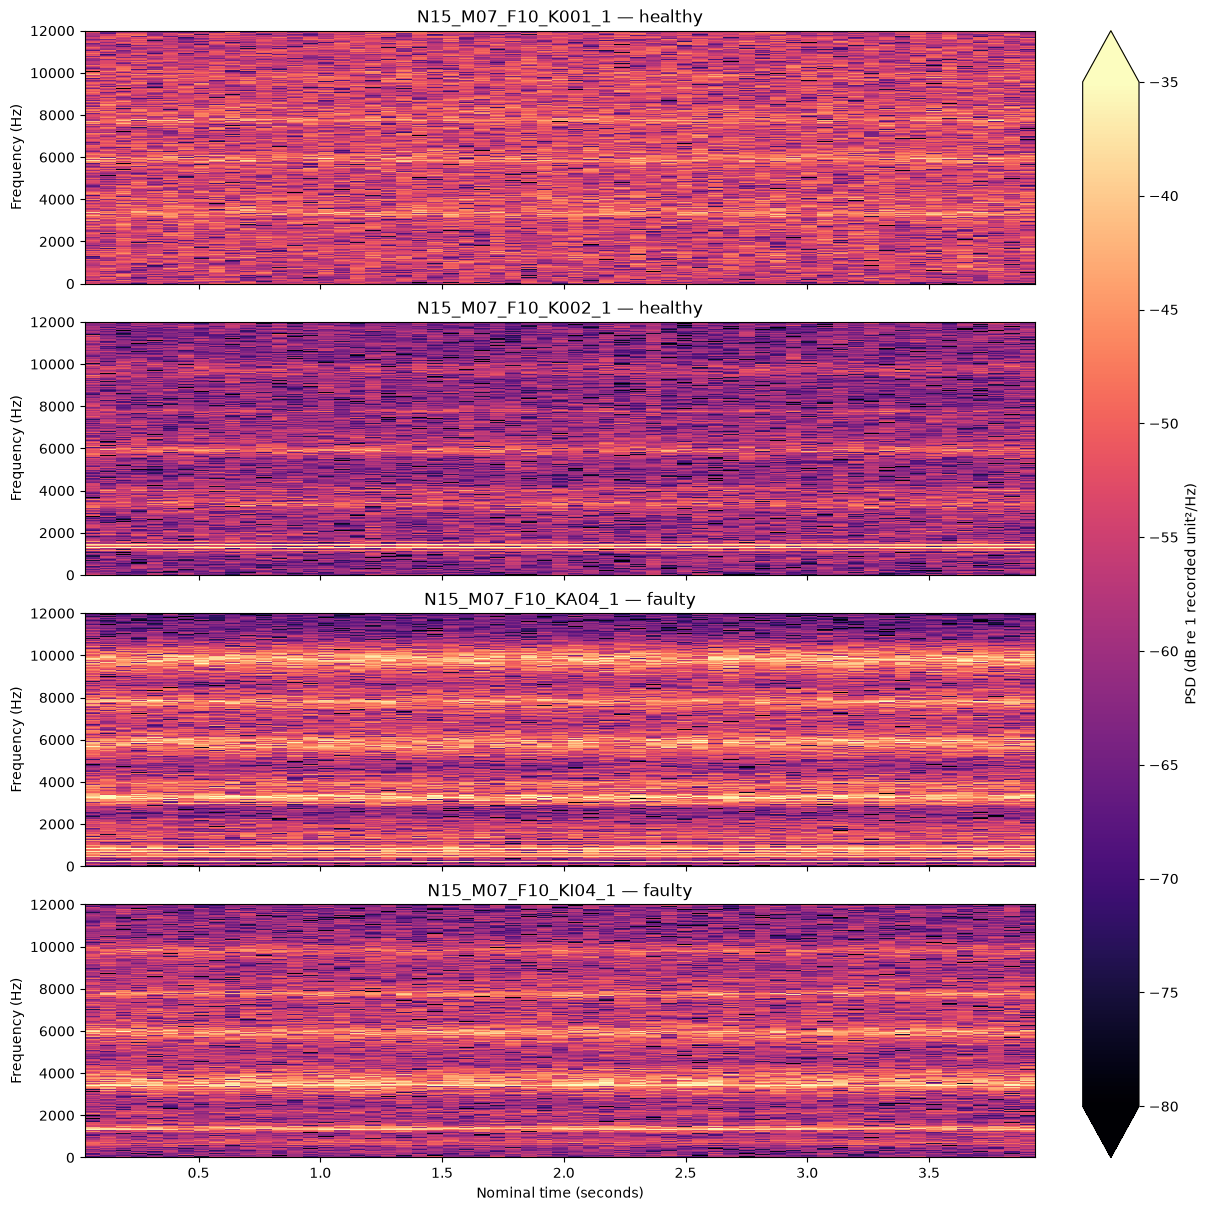

In [22]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(12, 12),
    sharex=True,
    sharey=True,
    layout="constrained"
)

for ax, (_, row) in zip(axes, example_records.iterrows()):
    # Load this recording.
    x, _ = load_vibration(raw_folder / row["relative_path"])
    fs = float(row["nominal_fs_hz"])

    # Keep the same spectrogram settings for every recording.
    frequencies, times, power = spectrogram(
        x,
        fs=fs,
        window="hann",
        nperseg=8192,
        noverlap=4096,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    # Convert power density to decibels.
    power_db = 10 * np.log10(np.maximum(power, 1e-12))

    # Use identical colours for identical PSD values.
    mesh = ax.pcolormesh(
        times, frequencies, power_db,
        shading="auto",
        cmap="magma",
        vmin=-80,
        vmax=-35
    )

    ax.set_title(f"{row['recording_id']} — {row['condition']}")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_ylim(0, 12_000)

axes[-1].set_xlabel("Nominal time (seconds)")
fig.colorbar(
    mesh,
    ax=axes,
    label="PSD (dB re 1 recorded unit²/Hz)",
    extend="both"
)

plt.show()

In [23]:
# Select K001 repetitions from our existing comparison pool.
k001_records = comparison_pool[
    comparison_pool["bearing_id"] == "K001"
].sort_values("recording_no")

# Collect one PSD per recording.
psd_list = []

for _, row in k001_records.iterrows():
    x, _ = load_vibration(raw_folder / row["relative_path"])
    fs = float(row["nominal_fs_hz"])

    f_repeat, power = welch(
        x,
        fs=fs,
        window="hann",
        nperseg=8192,
        noverlap=4096,
        detrend="constant",
        scaling="density"
    )

    psd_list.append(power)

# Arrange the results into a matrix.
psd_matrix = np.stack(psd_list)

print("Recordings:", len(k001_records))
print("PSD matrix shape:", psd_matrix.shape)

Recordings: 16
PSD matrix shape: (16, 4097)


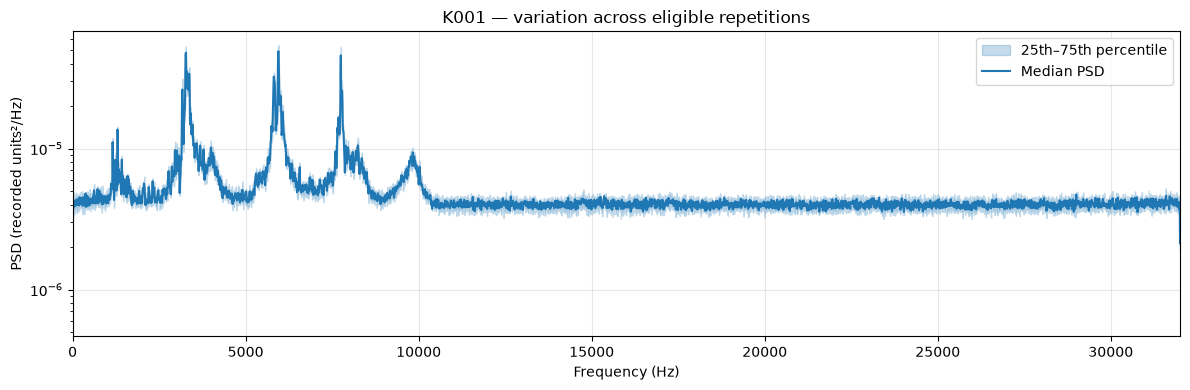

In [24]:
# Summarize the 16 PSD values at each frequency.
median_psd = np.median(psd_matrix, axis=0)
q25, q75 = np.percentile(psd_matrix, [25, 75], axis=0)

fig, ax = plt.subplots(figsize=(12, 4))

# Show the middle 50% of PSD values.
ax.fill_between(
    f_repeat, q25, q75,
    color="tab:blue",
    alpha=0.25,
    label="25th–75th percentile"
)

# Show the typical PSD.
ax.semilogy(
    f_repeat, median_psd,
    color="tab:blue",
    label="Median PSD"
)

ax.set(
    xlabel="Frequency (Hz)",
    ylabel="PSD (recorded units²/Hz)",
    title="K001 — variation across eligible repetitions",
    xlim=(0, fs / 2)
)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

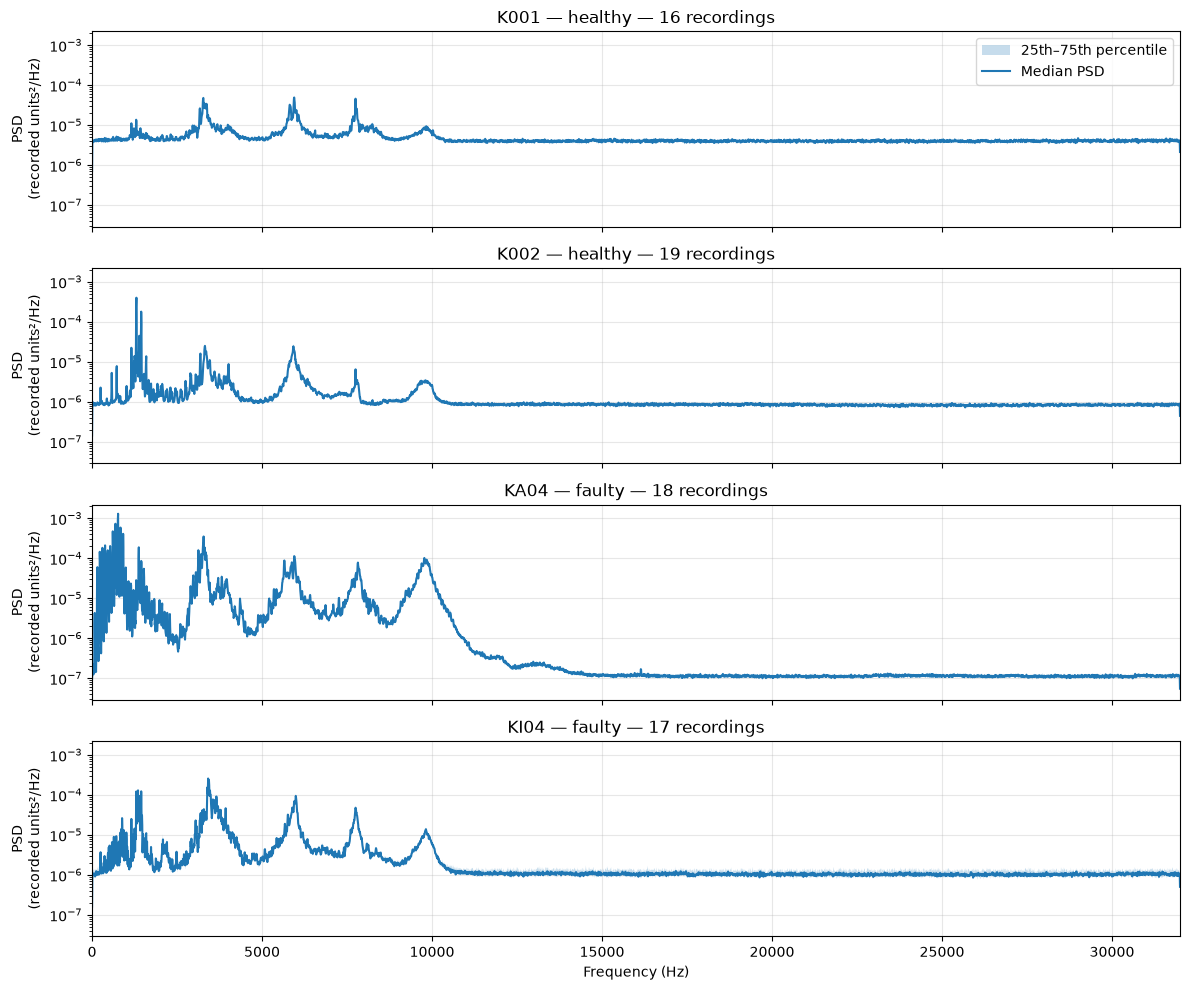

In [ ]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 10),
    sharex=True, sharey=True
)

for ax, (bearing_id, records) in zip(
    axes, comparison_pool.groupby("bearing_id")
):
    psd_list = []

    # Calculate one PSD per eligible recording.
    for _, row in records.iterrows():
        x, _ = load_vibration(raw_folder / row["relative_path"])
        fs = float(row["nominal_fs_hz"])

        frequencies, power = welch(
            x,
            fs=fs,
            window="hann",
            nperseg=8192,
            noverlap=4096,
            detrend="constant",
            scaling="density"
        )

        psd_list.append(power)

    # Summarize across recordings at each frequency.
    matrix = np.stack(psd_list)
    median = np.median(matrix, axis=0)
    q25, q75 = np.percentile(matrix, [25, 75], axis=0)

    ax.fill_between(
        frequencies, q25, q75,
        alpha=0.25, label="25th–75th percentile"
    )
    ax.semilogy(frequencies, median, label="Median PSD")

    condition = records["condition"].iloc[0]
    ax.set_title(
        f"{bearing_id} — {condition} — {len(records)} recordings"
    )
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, fs / 2)

plt.tight_layout()
plt.show()

In [26]:
setting_counts = (
    analysis_development
    .groupby(["speed_code", "torq_code", "force_code", "bearing_id"])
    .size()
    .unstack("bearing_id", fill_value=0)
)

print(setting_counts)
print("\nTotal eligible recordings:", setting_counts.to_numpy().sum())

bearing_id                       K001  K002  KA04  KI04
speed_code torq_code force_code                        
N09        M07       F10           16    18    19    16
N15        M01       F10           16    18    17    19
           M07       F04           10    20    18    15
                     F10           16    19    18    17

Total eligible recordings: 272


In [27]:
low_speed_pool = analysis_development[
    (analysis_development["speed_code"] == "N09")
    & (analysis_development["torq_code"] == "M07")
    & (analysis_development["force_code"] == "F10")
].copy()

print(low_speed_pool.groupby("bearing_id").size())

bearing_id
K001    16
K002    18
KA04    19
KI04    16
dtype: int64


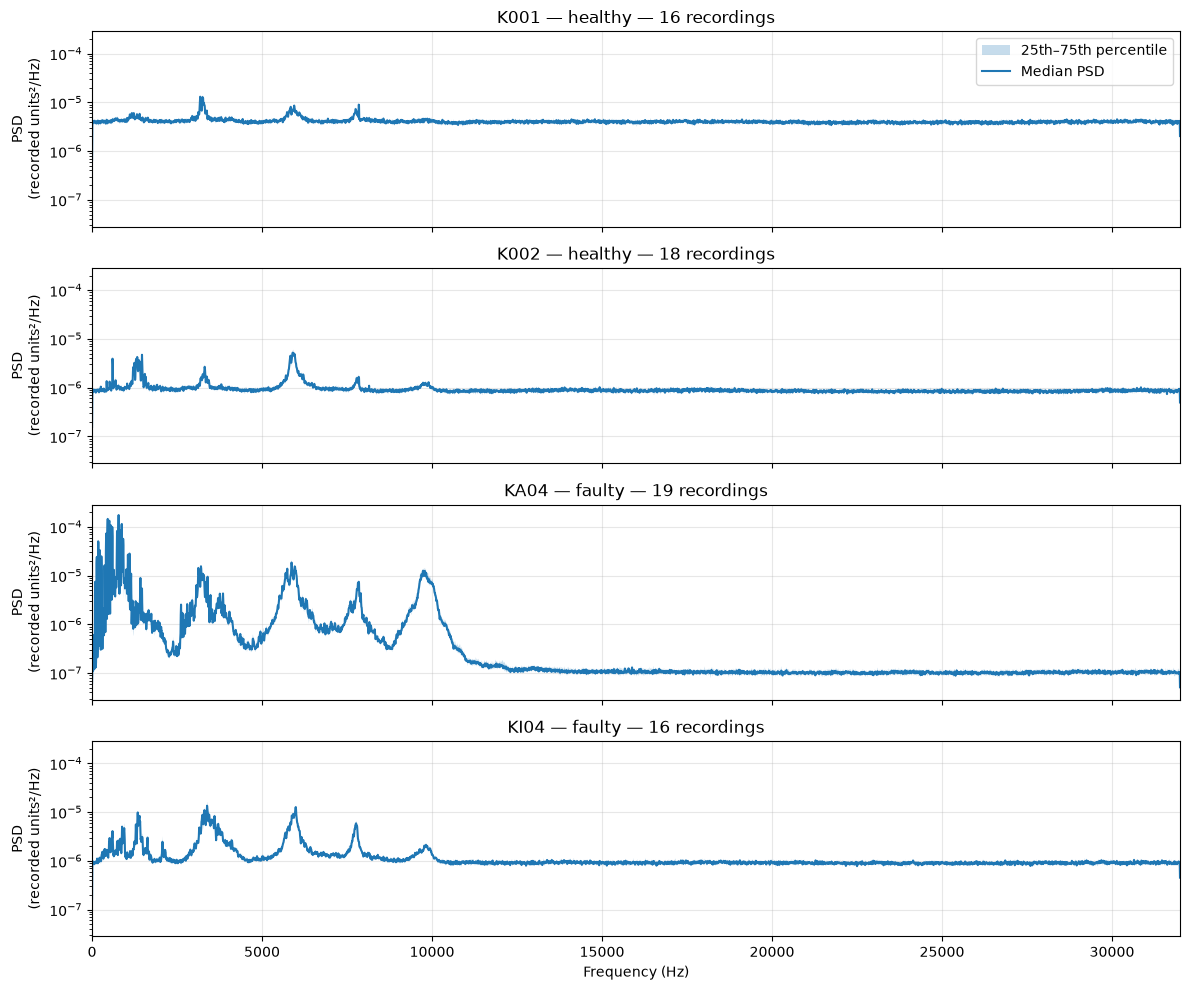

In [28]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 10),
    sharex=True, sharey=True
)

for ax, (bearing_id, records) in zip(
    axes, low_speed_pool.groupby("bearing_id")
):
    psd_list = []

    # Calculate one PSD per eligible recording.
    for _, row in records.iterrows():
        x, _ = load_vibration(raw_folder / row["relative_path"])
        fs = float(row["nominal_fs_hz"])

        frequencies, power = welch(
            x,
            fs=fs,
            window="hann",
            nperseg=8192,
            noverlap=4096,
            detrend="constant",
            scaling="density"
        )

        psd_list.append(power)

    # Summarize across recordings at each frequency.
    matrix = np.stack(psd_list)
    median = np.median(matrix, axis=0)
    q25, q75 = np.percentile(matrix, [25, 75], axis=0)

    ax.fill_between(
        frequencies, q25, q75,
        alpha=0.25, label="25th–75th percentile"
    )
    ax.semilogy(frequencies, median, label="Median PSD")

    condition = records["condition"].iloc[0]
    ax.set_title(
        f"{bearing_id} — {condition} — {len(records)} recordings"
    )
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, fs / 2)

plt.tight_layout()
plt.show()

In [29]:
low_torque_pool = analysis_development[
    (analysis_development["speed_code"] == "N15")
    & (analysis_development["torq_code"] == "M01")
    & (analysis_development["force_code"] == "F10")
].copy()

print(low_torque_pool.groupby("bearing_id").size())

bearing_id
K001    16
K002    18
KA04    17
KI04    19
dtype: int64


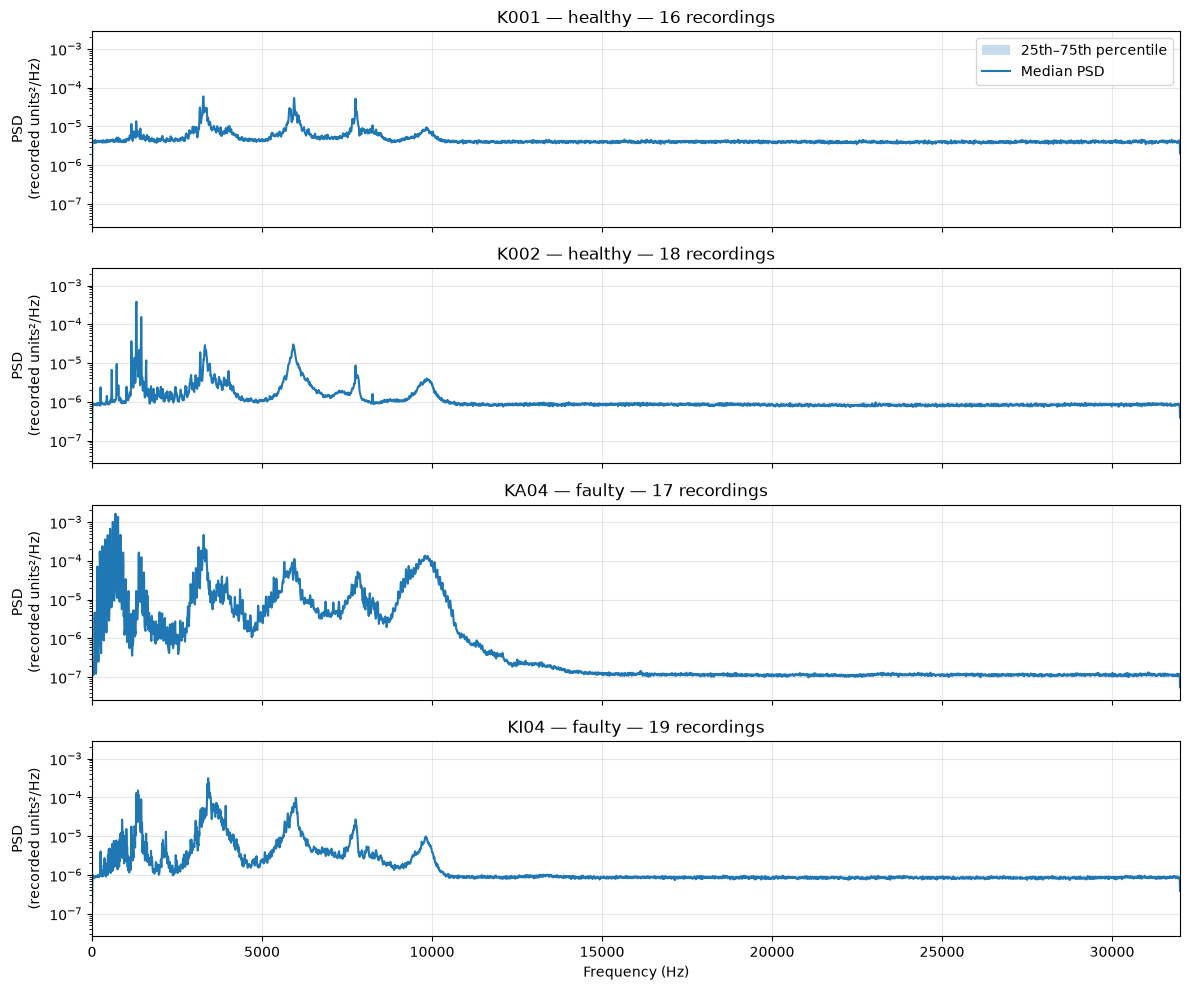

In [30]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 10),
    sharex=True, sharey=True
)
for ax, (bearing_id, records) in zip(
    axes, low_torque_pool.groupby("bearing_id")
):
    psd_list = []

    # Calculate one PSD per eligible recording.
    for _, row in records.iterrows():
        x, _ = load_vibration(raw_folder / row["relative_path"])
        fs = float(row["nominal_fs_hz"])

        frequencies, power = welch(
            x,
            fs=fs,
            window="hann",
            nperseg=8192,
            noverlap=4096,
            detrend="constant",
            scaling="density"
        )

        psd_list.append(power)

    # Summarize across recordings at each frequency.
    matrix = np.stack(psd_list)
    median = np.median(matrix, axis=0)
    q25, q75 = np.percentile(matrix, [25, 75], axis=0)

    ax.fill_between(
        frequencies, q25, q75,
        alpha=0.25, label="25th–75th percentile"
    )
    ax.semilogy(frequencies, median, label="Median PSD")

    condition = records["condition"].iloc[0]
    ax.set_title(
        f"{bearing_id} — {condition} — {len(records)} recordings"
    )
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, fs / 2)

plt.tight_layout()
plt.show()

In [31]:
low_force_pool = analysis_development[
    (analysis_development["speed_code"] == "N15")
    & (analysis_development["torq_code"] == "M07")
    & (analysis_development["force_code"] == "F04")
].copy()

print(low_force_pool.groupby("bearing_id").size())

bearing_id
K001    10
K002    20
KA04    18
KI04    15
dtype: int64


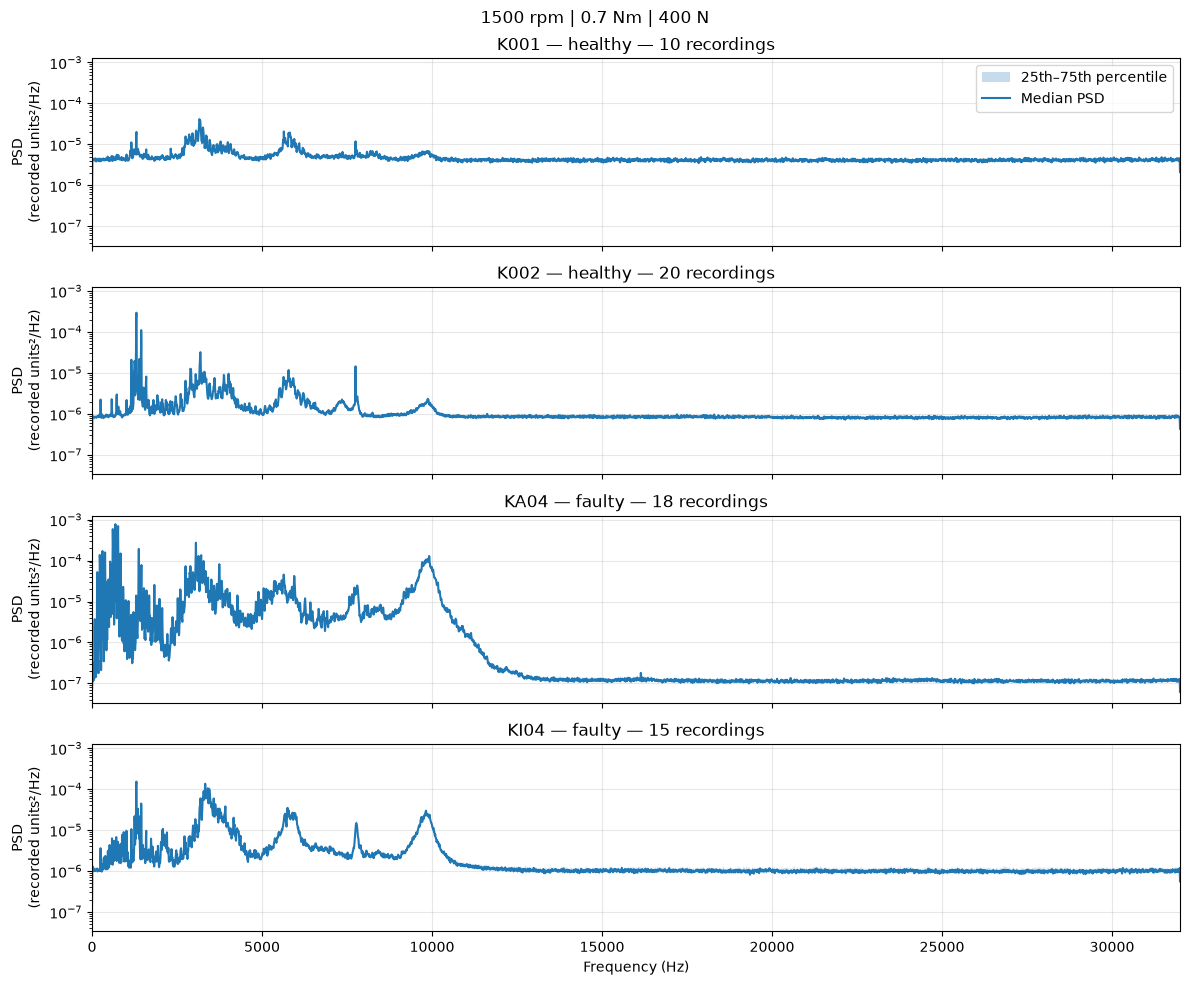

In [32]:
fig, axes = plt.subplots(
    4, 1, figsize=(12, 10),
    sharex=True, sharey=True
)
for ax, (bearing_id, records) in zip(
    axes, low_force_pool.groupby("bearing_id")
):
    psd_list = []

    # Calculate one PSD per eligible recording.
    for _, row in records.iterrows():
        x, _ = load_vibration(raw_folder / row["relative_path"])
        fs = float(row["nominal_fs_hz"])

        frequencies, power = welch(
            x,
            fs=fs,
            window="hann",
            nperseg=8192,
            noverlap=4096,
            detrend="constant",
            scaling="density"
        )

        psd_list.append(power)

    # Summarize across recordings at each frequency.
    matrix = np.stack(psd_list)
    median = np.median(matrix, axis=0)
    q25, q75 = np.percentile(matrix, [25, 75], axis=0)

    ax.fill_between(
        frequencies, q25, q75,
        alpha=0.25, label="25th–75th percentile"
    )
    ax.semilogy(frequencies, median, label="Median PSD")

    condition = records["condition"].iloc[0]
    ax.set_title(
        f"{bearing_id} — {condition} — {len(records)} recordings"
    )
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Frequency (Hz)")
axes[-1].set_xlim(0, fs / 2)
fig.suptitle("1500 rpm | 0.7 Nm | 400 N")
plt.tight_layout()
plt.show()